In [3]:
import glob

import xarray as xr

buoy_files = sorted(glob.glob("inputs/raw_buoys_Johan/*"))
print(buoy_files)
for buoy_file in buoy_files:
    buoy = xr.open_dataset(buoy_file)
    print(
        buoy.attrs["Lon"],
        buoy.attrs["Lat"],
        buoy.attrs["location_messageid"],
        # buoy.time.min().values,
        # buoy.time.max().values,
    )


def preprocess_buoy_data(ds):
    ds = ds[["Hm0", "Tm-10", "Th0"]].expand_dims(
        {"buoy": [int(ds.attrs["location_messageid"])]}
    )
    ds = ds.assign_coords({"lon": ("buoy", [ds.attrs["Lon"]])})
    ds = ds.assign_coords({"lat": ("buoy", [ds.attrs["Lat"]])})
    ds.attrs = {}
    return ds


buoysitas = xr.open_mfdataset(
    buoy_files, preprocess=preprocess_buoy_data, concat_dim="buoy", combine="nested"
).load()
buoysitas

['inputs/raw_buoys_Johan/amelanderzeegat.1.1-Amelander_zeegat_1_1.nc', 'inputs/raw_buoys_Johan/amelanderzeegat.1.2-Amelander_zeegat_1_2.nc', 'inputs/raw_buoys_Johan/eierlandsegat-Eierlandse_Gat.nc', 'inputs/raw_buoys_Johan/eurogeul.e13-Eurogeul_E13.nc', 'inputs/raw_buoys_Johan/ijmuiden.munitiestort.1-IJmuiden_munitiestort_1.nc', 'inputs/raw_buoys_Johan/petten.meetraai1-Petten_meetraai_01.nc', 'inputs/raw_buoys_Johan/stortemelk.west-Stortemelk_west.nc', 'inputs/raw_buoys_Johan/westereems.west-Westereems_west.nc', 'inputs/raw_buoys_Johan/zandmoter.boei.noord-Zandmoter_boei_noord.nc']
5.481405 53.507601 8851
5.48442 53.507598 18354
4.660347 53.2762 16670
3.741804 52.009184 8991
4.057019 52.549225 8664
4.556779 52.806846 2275
4.995998 53.320717 3075
6.366667 53.618056 16702
4.158267 52.048094 8226


/tmp/ipykernel_1223738/3461402975.py:28: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  buoysitas = xr.open_mfdataset(


<xarray.Dataset> Size: 223MB
Dimensions:  (buoy: 9, time: 997313)
Coordinates:
  * buoy     (buoy) int64 72B 8851 18354 16670 8991 8664 2275 3075 16702 8226
  * time     (time) datetime64[ns] 8MB 2000-01-01 ... 2022-03-01
    lon      (buoy) float64 72B 5.481 5.484 4.66 3.742 ... 4.996 6.367 4.158
    lat      (buoy) float64 72B 53.51 53.51 53.28 52.01 ... 53.32 53.62 52.05
Data variables:
    Hm0      (buoy, time) float64 72MB nan nan nan nan nan ... nan nan nan nan
    Tm-10    (buoy, time) float64 72MB nan nan nan nan nan ... nan nan nan nan
    Th0      (buoy, time) float64 72MB nan nan nan nan nan ... nan nan nan nan

In [4]:
buoysitas["Hm0"] = buoysitas["Hm0"] / 100
buoysitas.attrs = {"projection": "ETRS89"}
buoysitas

<xarray.Dataset> Size: 223MB
Dimensions:  (buoy: 9, time: 997313)
Coordinates:
  * buoy     (buoy) int64 72B 8851 18354 16670 8991 8664 2275 3075 16702 8226
  * time     (time) datetime64[ns] 8MB 2000-01-01 ... 2022-03-01
    lon      (buoy) float64 72B 5.481 5.484 4.66 3.742 ... 4.996 6.367 4.158
    lat      (buoy) float64 72B 53.51 53.51 53.28 52.01 ... 53.32 53.62 52.05
Data variables:
    Hm0      (buoy, time) float64 72MB nan nan nan nan nan ... nan nan nan nan
    Tm-10    (buoy, time) float64 72MB nan nan nan nan nan ... nan nan nan nan
    Th0      (buoy, time) float64 72MB nan nan nan nan nan ... nan nan nan nan
Attributes:
    projection:  ETRS89

In [5]:
era5_data = xr.open_dataset("inputs/ERA5_forcing_goals_2000_2025.nc")
era5_data

<xarray.Dataset> Size: 184MB
Dimensions:    (time: 227928, goal: 10)
Coordinates:
  * time       (time) datetime64[ns] 2MB 2000-01-01 ... 2025-12-31T23:00:00
  * goal       (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    latitude   (goal) float64 80B ...
    longitude  (goal) float64 80B ...
Data variables: (12/20)
    wmb        (time, goal) float32 9MB ...
    swh        (time, goal) float32 9MB ...
    mwp        (time, goal) float32 9MB ...
    pp1d       (time, goal) float32 9MB ...
    mwd        (time, goal) float32 9MB ...
    wdw        (time, goal) float32 9MB ...
    ...         ...
    swh2       (time, goal) float32 9MB ...
    mwp2       (time, goal) float32 9MB ...
    mwd2       (time, goal) float32 9MB ...
    swh3       (time, goal) float32 9MB ...
    mwp3       (time, goal) float32 9MB ...
    mwd3       (time, goal) float32 9MB ...
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2025-05-05T16:51 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts

In [6]:
import numpy as np

closest_goal_to_buoy = [
    np.sqrt(
        (era5_data.longitude.values - buoy_lon) ** 2
        + (era5_data.latitude.values - buoy_lat) ** 2
    ).argmin()
    + 1
    for buoy_lon, buoy_lat in zip(buoysitas.lon.values, buoysitas.lat.values)
]
closest_goal_to_buoy

[4, 4, 6, 8, 7, 7, 6, 2, 8]

In [7]:
buoysitas = buoysitas.assign_coords({"closest_goal": ("buoy", closest_goal_to_buoy)})
buoysitas

<xarray.Dataset> Size: 223MB
Dimensions:       (buoy: 9, time: 997313)
Coordinates:
  * buoy          (buoy) int64 72B 8851 18354 16670 8991 ... 3075 16702 8226
  * time          (time) datetime64[ns] 8MB 2000-01-01 ... 2022-03-01
    lon           (buoy) float64 72B 5.481 5.484 4.66 ... 4.996 6.367 4.158
    lat           (buoy) float64 72B 53.51 53.51 53.28 ... 53.32 53.62 52.05
    closest_goal  (buoy) int64 72B 4 4 6 8 7 7 6 2 8
Data variables:
    Hm0           (buoy, time) float64 72MB nan nan nan nan ... nan nan nan nan
    Tm-10         (buoy, time) float64 72MB nan nan nan nan ... nan nan nan nan
    Th0           (buoy, time) float64 72MB nan nan nan nan ... nan nan nan nan
Attributes:
    projection:  ETRS89

In [8]:
buoysitas["depth"] = (
    ("buoy"),
    [-19.2, -19.3, -28.0, -24.3, -24.8, -20.0, -11.15, -14.8, -11.1],
)
buoysitas

<xarray.Dataset> Size: 223MB
Dimensions:       (buoy: 9, time: 997313)
Coordinates:
  * buoy          (buoy) int64 72B 8851 18354 16670 8991 ... 3075 16702 8226
  * time          (time) datetime64[ns] 8MB 2000-01-01 ... 2022-03-01
    lon           (buoy) float64 72B 5.481 5.484 4.66 ... 4.996 6.367 4.158
    lat           (buoy) float64 72B 53.51 53.51 53.28 ... 53.32 53.62 52.05
    closest_goal  (buoy) int64 72B 4 4 6 8 7 7 6 2 8
Data variables:
    Hm0           (buoy, time) float64 72MB nan nan nan nan ... nan nan nan nan
    Tm-10         (buoy, time) float64 72MB nan nan nan nan ... nan nan nan nan
    Th0           (buoy, time) float64 72MB nan nan nan nan ... nan nan nan nan
    depth         (buoy) float64 72B -19.2 -19.3 -28.0 ... -11.15 -14.8 -11.1
Attributes:
    projection:  ETRS89

In [9]:
buoysitas.to_netcdf("inputs/Processed_Johan_Buoys.nc")

In [12]:
print(buoysitas.Hm0.dropna(dim="time").time.min())
print(buoysitas.Hm0.dropna(dim="time").time.max())

<xarray.DataArray 'time' ()> Size: 8B
array('2011-12-02T23:10:00.000000000', dtype='datetime64[ns]')
<xarray.DataArray 'time' ()> Size: 8B
array('2011-12-31T22:50:00.000000000', dtype='datetime64[ns]')


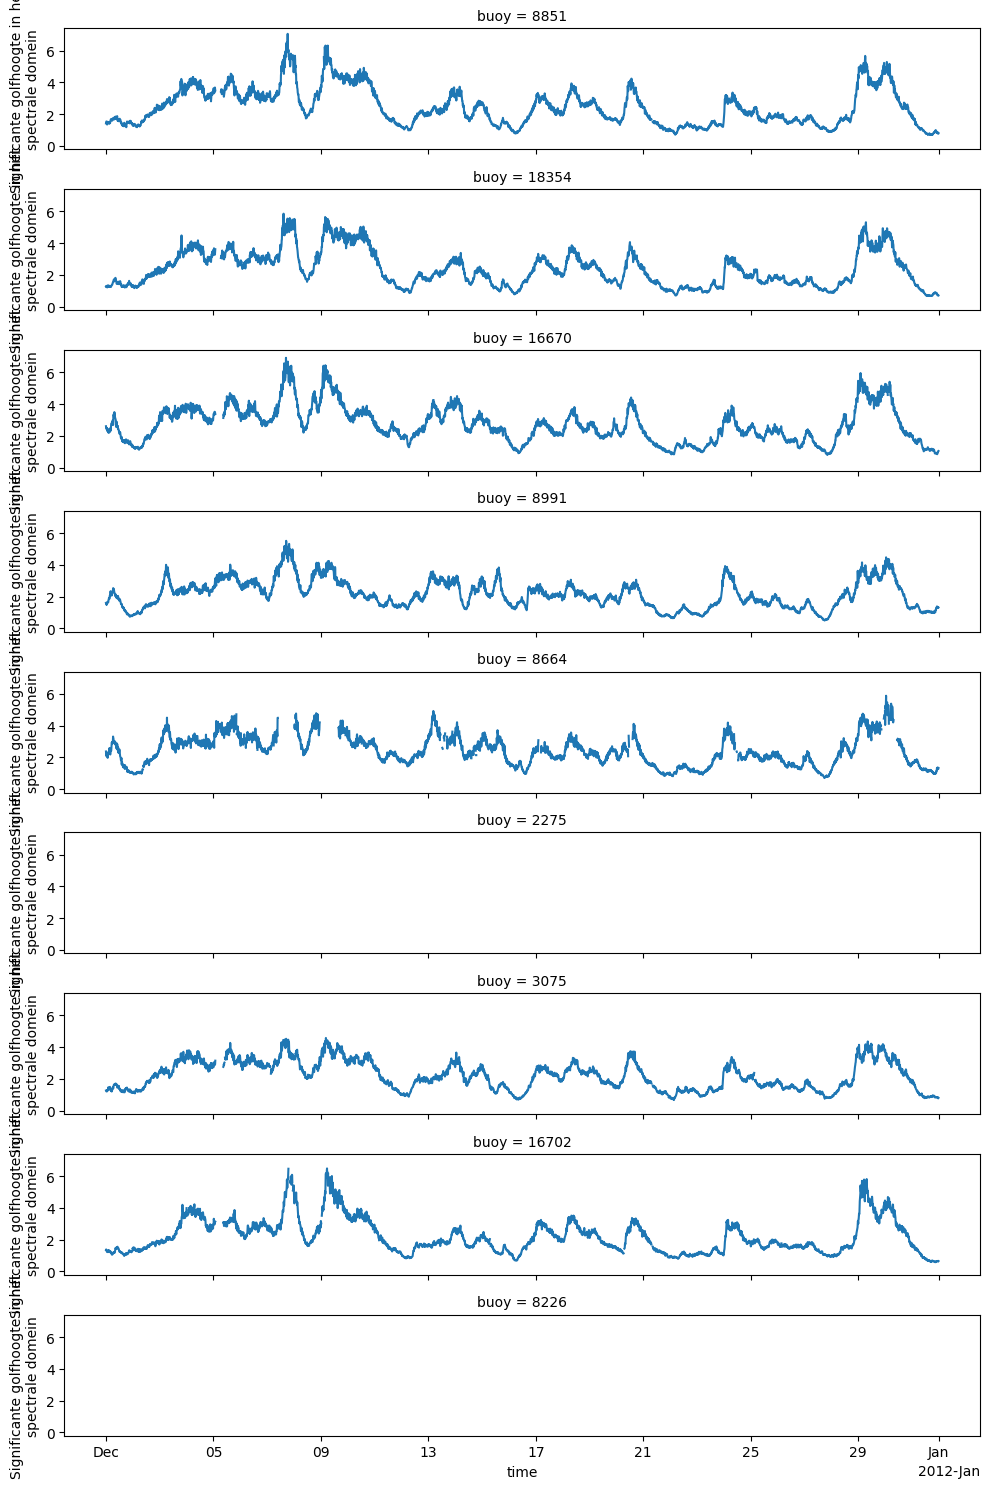

In [ ]:
buoysitas.Hm0.dropna(dim="time").sel(time="2011-12").plot(row="buoy", figsize=(10, 15))